In [1]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

print("Ready! OSMnx version", ox.__version__)

#Imported everything I may need

Ready! OSMnx version 1.5.0


In [2]:
CITY = "Leuven, Belgium"  # or "Leuven, Belgium", "Popayán, Colombia", your home town...
G_city = ox.graph_from_place(CITY, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
parks = ox.features_from_place(CITY, tags={"leisure": "park"}).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = ox.features_from_place(CITY, tags={"building": True}).to_crs(crs)

#I did try usung alternative cities however none would work bar Leuven so continued using that city
#Replicated importing logic from 7.1

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pa

In [3]:
import overturemaps

LEUVEN_BOX = (4.67, 50.86, 4.73, 50.90)    

table = overturemaps.record_batch_reader("place", bbox=LEUVEN_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326")
places["name"] = places["names"].str.get("primary")      

print(len(places), "Overture places in Leuven")
#Imported logic from 4.1, converted coordinates to be Leuven specific, similarly with EPSG
#Done to gather places in Leuven in order to track certain amenities/services

6110 Overture places in Leuven


In [5]:
places["basic_category"].value_counts().head(60)
#Witness what labels we will be dealing with in order to dwindle what we want down with str. 

basic_category
restaurant                              460
fashion_and_apparel_store               282
personal_or_beauty_service              235
corporate_or_business_office            226
professional_service                    213
social_or_community_service             184
hospital                                130
real_estate_service                     130
design_service                          124
casual_eatery                           123
bar                                     122
home_service                            106
food_and_beverage_store                 105
college_university                      103
behavioral_or_mental_health_clinic      101
financial_service                        94
hardware_home_and_garden_store           86
physical_medicine_and_rehabilitation     84
event_or_party_service                   82
diagnostics_imaging_or_lab_service       81
cafe                                     77
campus_building                          75
media_service    

In [4]:
is_schools = places["basic_category"].str.contains("school|learning", na=False)
overture_schools = places[is_schools & (places["confidence"] >= 0.5)].copy()

print(overture_schools["basic_category"].value_counts())
print()
print("Schools schools in Overture:", len(overture_schools))

#Continued using confidence of 0.5 as deemed it adequate, used str. school and learning as examining basic categories that's what seemed to arise. 

basic_category
elementary_school    28
specialty_school     26
place_of_learning    22
high_school           6
preschool             2
Name: count, dtype: int64

Schools schools in Overture: 84


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [5]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
overture_schools = overture_schools.to_crs(crs)

print(overture_schools.crs)
print(overture_schools.total_bounds)

#converted crs with city_nodes, edges, and our new overture schools as map wouldnt load correctly without it.

+proj=utm +zone=31 +ellps=WGS84 +datum=WGS84 +units=m +no_defs +type=crs
[ 617660.36210944 5635783.88737249  621675.10947486 5639854.33908541]


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\IPython\core\pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


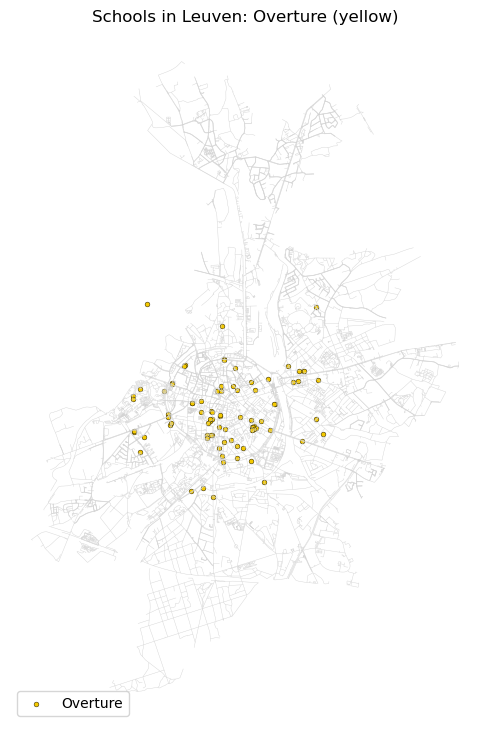

In [6]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
overture_schools.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Schools in Leuven: Overture (yellow)")
ax.set_axis_off()
plt.show()
#Used plotting logic from 4.3 however this time only plotting overture, omitting OSM

In [7]:
is_healthcare = places["basic_category"].str.contains("pharmacy|clinic|hospital", na=False)
overture_healthcare = places[is_healthcare & (places["confidence"] >= 0.5)].copy()

print(overture_healthcare["basic_category"].value_counts())
print()
print("Healthcare in Overture:", len(overture_healthcare))

#Identical logic as prior however this time with healthcare, str. 3 this time as deemed appropriate. 

basic_category
hospital                              124
behavioral_or_mental_health_clinic     95
dental_clinic                          53
pharmacy_and_drug_store                46
vision_or_eye_care_clinic              13
primary_care_or_general_clinic          8
urgent_care_clinic                      1
specialty_hospital                      1
pediatric_clinic                        1
Name: count, dtype: int64

Healthcare in Overture: 342


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [8]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)

overture_healthcare = overture_healthcare.to_crs(crs)

#Same crs conversion logic

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


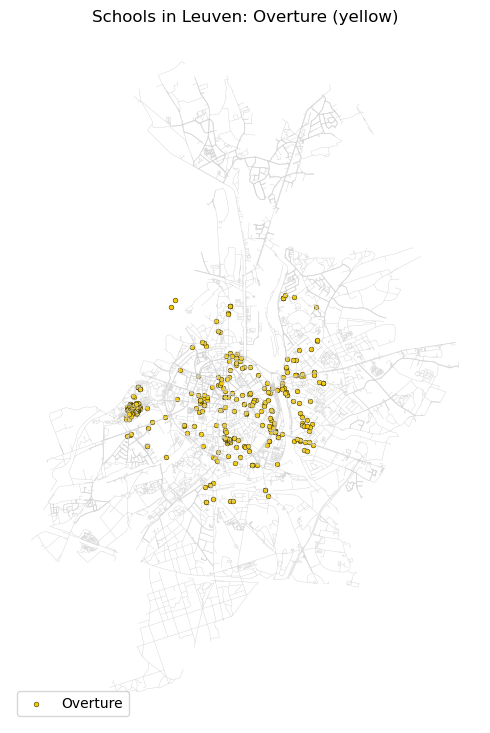

In [9]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
overture_healthcare.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Schools in Leuven: Overture (yellow)")
ax.set_axis_off()
plt.show()

#Same plotting logic

In [10]:
schools = overture_schools
schools["service"] = "Schools"

healthcare = overture_healthcare
healthcare["service"] = "Healthcare"

services = pd.concat([schools, healthcare])

#In order to carry out the following imported code from the excercies,
#I had to define our subsections of healthcare and schools into each of their parts otherwise was having difficulties. 


C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [11]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)

    return unary_union(list(streets.buffer(50)))

#Defining isochrone as in 6.1, similar buffer as again deemed appropriate

# Sidenote, the following two steps you need to activate one to then activate the other, to then run the original again

In [18]:
LEUVEN = (50.8796, 4.7009) 
AREA = 2000
WALK_SPEED = 80

centre = gpd.GeoSeries.from_xy([LEUVEN[1]], [LEUVEN[0]], crs="EPSG:4326").to_crs(crs)
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

#Set leuven coordinates along with area and walk speed, while defining centre, as seen in 5.3 and later. 
#Would put this later but need it for the following step:

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pyproj\transformer.py:820: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return self._transformer._transform_point(


In [17]:
G_walk = ox.graph_from_point(LEUVEN, dist=AREA, network_type="walk")
G_walk = ox.project_graph(G_walk).to_undirected()

print("Walk network:", len(G_walk), "junctions")

#Imported code from 5.2, however omitting cycle data as its not relevant

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pa

Walk network: 8189 junctions


In [19]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])
#In order to define our junction nearest the centre, imported from 6.2, will be relevant later 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [20]:
iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)

#Imported again 6.2, defining iso15 now as map creation would not be plausable without it.
#Set bounds 1400 as it zooms in better without omitting any data, easier visualisation.

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


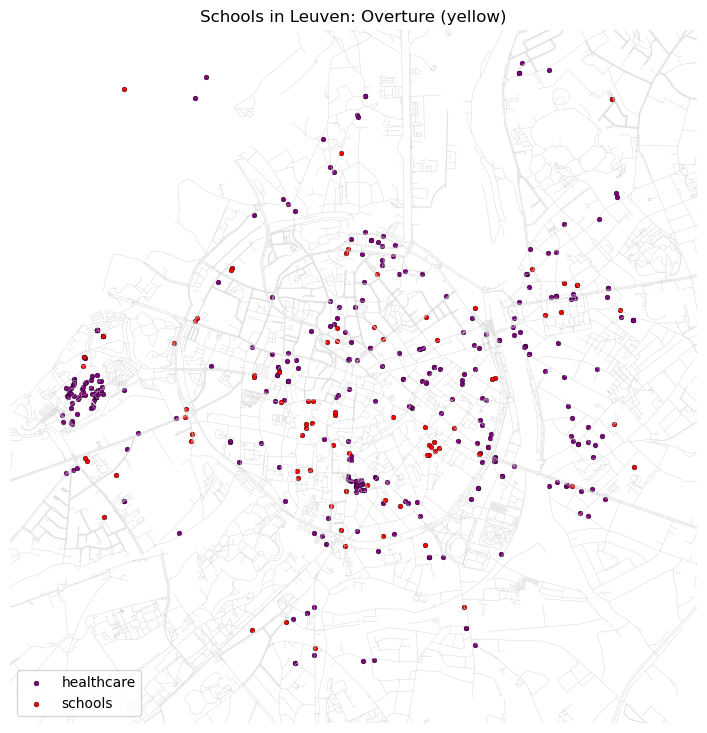

In [21]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
overture_healthcare.plot(ax=ax, color="purple", markersize=12, label="healthcare", edgecolor="black", linewidth=0.3)
overture_schools.plot(ax=ax, color="red", markersize=12, label="schools", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 1400, iso15.bounds[2] + 1400)
ax.set_ylim(iso15.bounds[1] - 1400, iso15.bounds[3] + 1400)
ax.set_title("Schools in Leuven: Overture (yellow)")
ax.set_axis_off()
plt.show()

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pa

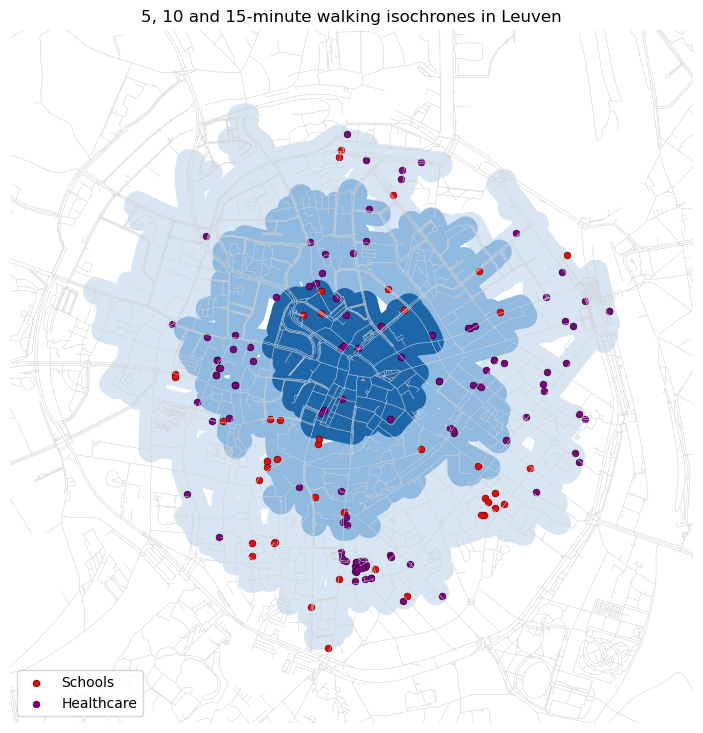

service
Healthcare    117
Schools        44
Name: count, dtype: int64


In [22]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_walk, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs=crs).plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]
for name, colour in zip(["Schools", "Healthcare"], ["red", "purple"]):
    inside[inside["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walking isochrones in Leuven")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts())

#Map creation to identify, Schools and Healthcare within each 15, 10, and 5, boundaries. 
#Similar logic as in 6.2, however as you can see I have managed to use my new Schools and Healthcare labels instead of SERVICES as in example.


In [24]:
isochrones = {
    5: isochrone(G_walk, home, 5 * WALK_SPEED),
    10: isochrone(G_walk, home, 10 * WALK_SPEED),
    15: isochrone(G_walk, home, 15 * WALK_SPEED)}

#Defining Isochrone to be able to create a table with numbers based on each variable

In [25]:
results = pd.DataFrame(index=list(isochrones))
results["Schools"] = [services[services.within(isochrones[s])]["service"].eq("Schools").sum() for s in isochrones]
results["Healthcare"] = [services[services.within(isochrones[s])]["service"].eq("Healthcare").sum() for s in isochrones]
results.round(0)

#Basic table displaying number of Schools and Healthcare in each minute band. 
#Converted logic from 5.5.

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pa

,Schools,Healthcare
5,4,16
10,20,55
15,44,117


In [26]:
CITY = "Leuven"
CATCHMENT = 1200

#Defining our city and catchement again for further analysis 

In [27]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()      
demand.head()

#Logic taken from 7.2 to snap parks and buildings to network 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


node
20917947      106
20917945      101
16571388       86
20975560       85
1400487492     83
Name: count, dtype: int64

In [28]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
parks[["name", "node"]].head()

#Identifying whether it worked based on names as I had issues with getting code for this,
#mixed up with St Andrews code way earlier when experimenting.
#I considered removing NaN however as it has a corresponding node and osmid chose not to. 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


name         node
element_type osmid                                  
way          8611804   Sint-Donatuspark   5135964060
             17412437     Katelijnenhof   2673438569
             21554732      Van Dalepark   6530044865
             21562211           't Fort  12850773343
             23002059               NaN     26818498

In [29]:
reach = {}          
ratio = {}          

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

#Imported from 7.3, park space per building, for each park 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


name   area_m2  m2_per_building
element_type osmid                                                           
way          294999180                Arenbergpark  666172.0           1047.0
             1531841510     Vijvers van Bellefroid  306190.0            843.0
relation     14437364    Provinciedomein Kessel-Lo  524713.0            341.0
way          21562211                      't Fort    9218.0            149.0
             1303111241           Park de Bunswyck   77496.0            103.0
relation     8321099     Alexianenpark Lemmenspark  120681.0             76.0
way          156178756                         NaN   56106.0             63.0
             570459619                Kloostertuin    8950.0             57.0
             294923733                   Lerkeveld   87556.0             41.0
             807559475             Dominicanenberg   28990.0             26.0

In [30]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       
homes_city["park_access"].describe().round(0)

#Imported from 7.4, adds up park space each home can reach. 

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


count    6857.0
mean       72.0
std       204.0
min         0.0
25%         4.0
50%        19.0
75%        31.0
max      1106.0
Name: park_access, dtype: float64

In [31]:
neighbourhood = centre.buffer(800).iloc[0]

#Created neighbourhood ring that you will see shortly, in order to limit homes within 800m of the centre

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


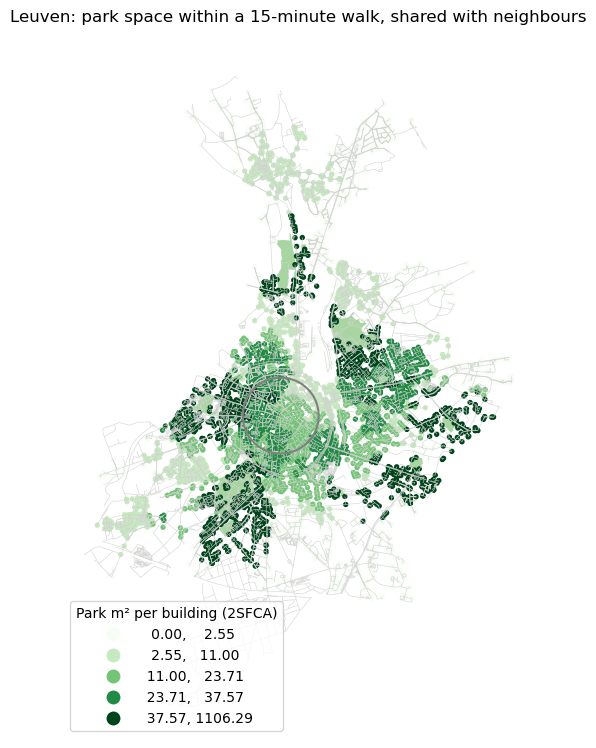

10% of homes have no park within a 15-minute walk


In [32]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
gpd.GeoSeries([neighbourhood], crs=crs).boundary.plot(ax=ax, color="grey")
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

#Displayed map overlayed with buffer ring. Similar logic as in 7.4.

In [33]:
homes_city = homes_city[homes_city.within(neighbourhood)]
parks = gpd.clip(parks, neighbourhood)
city_edges = gpd.clip(city_edges, neighbourhood)

#Clipping map to be within grey ring (800m boundary)

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pa

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


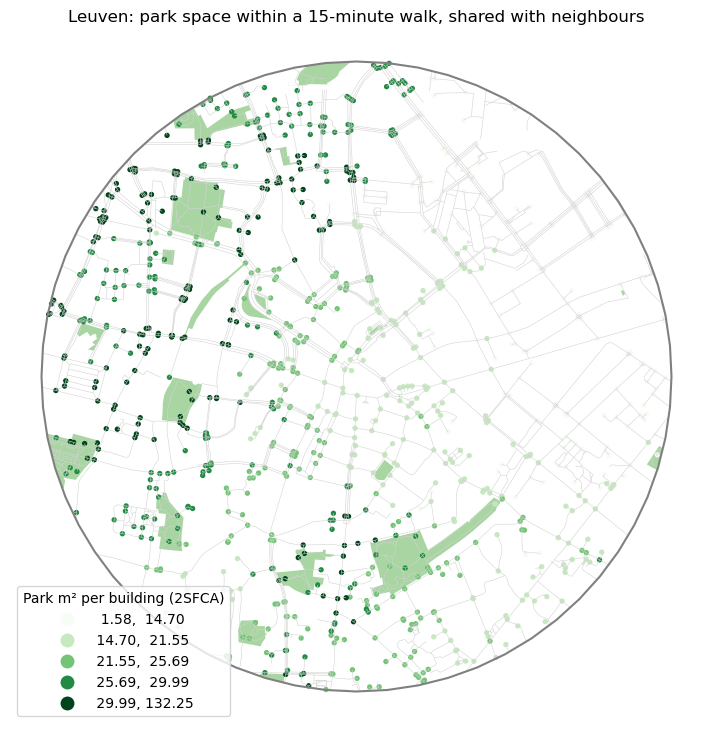

In [34]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
gpd.GeoSeries([neighbourhood], crs=crs).boundary.plot(ax=ax, color="grey")
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

#Displaying newly finished clipped map to 800m 

In [35]:
summary = pd.DataFrame({
    "Measure": [
        "Number of parks",
        "Number of buildings",
        "Number of homes within 800m",
        "Median park accessibility (m² per building)",
        "Homes with no park access (%)",
        "Schools within 15-minute walk",
        "Healthcare within 15-minute walk"],
    
    "Result": [len(parks), len(buildings), len(homes_city), homes_city["park_access"].median(),
        (homes_city["park_access"] == 0).mean() * 100,
        (services[services.within(iso15)]["service"] == "Schools").sum(),
        (services[services.within(iso15)]["service"] == "Healthcare").sum()]})

summary.round(1)

C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\Aaron\miniforge3\envs\ua_fresh\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


,Measure,Result
0,Number of parks,23.0
1,Number of buildings,42309.0
2,Number of homes within 800m,986.0
3,Median park accessibility (m² per building),23.4
4,Homes with no park access (%),0.0
5,Schools within 15-minute walk,44.0
6,Healthcare within 15-minute walk,117.0


The analysis suggests Leuven centre has good access to both green space, and essential services within agreeable walking distances. Access to services increases with walking time, as within 5 minutes there are 4 schools and 16 healthcare facilities, while at 15 minutes it rises to 44 schools and 117 healthcare facilities. Homes with 0% access to parks being 0 indicates every home has some access to greenspace within proximity to the centre which is great.  
Overall it does suggest services are largely accessable around Leuvens centre, however, accessibility may not be equal and its important to note data is dependant on Overture, therefore only assumptions can be made.